# Assignment 5 - S3 Momentum with Crash Control

Top momentum stocks, excluding high-volatility and high-beta names. Inverse-volatility weights.

## 1. Imports and Paths

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)

## 2. Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Parameters

In [4]:
N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000

MOMENTUM_FIELDS = ['ret_6_1', 'ret_9_1', 'ret_12_1', 'prc_highprc_252d']
MOMENTUM_TOP_PERCENTILE = 0.35
RISK_LOOKBACK_DAYS = 252 * 2
MAX_VOL_PERCENTILE = 0.85
MAX_BETA_PERCENTILE = 0.85
MAX_ABS_BETA = 1.50
MAX_STOCK_WEIGHT = 0.10

print('Momentum fields:', MOMENTUM_FIELDS)
print('Top momentum group:', MOMENTUM_TOP_PERCENTILE)

Momentum fields: ['ret_6_1', 'ret_9_1', 'ret_12_1', 'prc_highprc_252d']
Top momentum group: 0.35


## 4. Builder Functions

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def latest_jkp_before_rebalance(bs, rebdate, fields, lookback_days=460):
    fields = [field for field in fields if field in bs.data.jkp_data.columns]
    if not fields:
        raise ValueError('None of the requested JKP fields exist in jkp_data.')

    cutoff = pd.to_datetime(rebdate) - pd.Timedelta(days=1)
    start = cutoff - pd.Timedelta(days=lookback_days)
    dates = bs.data.jkp_data.index.get_level_values('date')
    window = bs.data.jkp_data.loc[(dates <= cutoff) & (dates >= start), fields]
    return window.groupby(level='id').last()


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    width = kwargs.get('width', RETURN_HISTORY_DAYS)
    min_obs = kwargs.get('min_obs', MIN_RETURN_OBS)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= min_obs).astype(int),
    })


def bibfn_selection_top_momentum(bs, rebdate, **kwargs):
    fields = kwargs.get('fields', MOMENTUM_FIELDS)
    top_percentile = kwargs.get('top_percentile', MOMENTUM_TOP_PERCENTILE)
    latest = latest_jkp_before_rebalance(bs, rebdate, fields)

    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    momentum_score = latest.rank(pct=True).mean(axis=1)
    threshold = momentum_score.quantile(1 - top_percentile)

    return pd.DataFrame({
        'values': momentum_score,
        'binary': momentum_score.ge(threshold).fillna(False).astype(int),
    })


def bibfn_selection_volatility_cap(bs, rebdate, **kwargs):
    width = kwargs.get('width', RISK_LOOKBACK_DAYS)
    max_percentile = kwargs.get('max_percentile', MAX_VOL_PERCENTILE)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(max_percentile)

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def bibfn_selection_beta_cap(bs, rebdate, **kwargs):
    width = kwargs.get('width', RISK_LOOKBACK_DAYS)
    max_percentile = kwargs.get('max_percentile', MAX_BETA_PERCENTILE)
    max_abs_beta = kwargs.get('max_abs_beta', MAX_ABS_BETA)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    bm = bs.data.bm_series.loc[ret.index.min():ret.index.max()].reindex(ret.index).dropna()
    ret = ret.reindex(index=bm.index)

    beta = ret.apply(lambda x: x.cov(bm) / bm.var() if bm.var() != 0 else np.nan, axis=0)
    threshold = beta.quantile(max_percentile)
    beta_limit = min(threshold, max_abs_beta)

    return pd.DataFrame({
        'values': beta,
        'binary': beta.le(beta_limit).fillna(False).astype(int),
    })


def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()


class InverseVolatilityPortfolio(Optimization):
    def __init__(self, max_weight=MAX_STOCK_WEIGHT, **kwargs):
        super().__init__(max_weight=max_weight, solver_name='no-solver-used', **kwargs)

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series']
        vol = ret.std(axis=0) * np.sqrt(252)
        inv_vol = 1 / vol.replace(0, np.nan)
        self.objective = Objective(inv_vol=inv_vol.dropna())

    def solve(self):
        inv_vol = self.objective.coefficients['inv_vol']
        weights = inv_vol / inv_vol.sum()
        weights = cap_and_redistribute(weights, self.params['max_weight'])
        self.results.update({'weights': weights.to_dict(), 'status': True})
        return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing Dates

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'top_momentum': SelectionItemBuilder(
        bibfn=bibfn_selection_top_momentum,
        fields=MOMENTUM_FIELDS,
        top_percentile=MOMENTUM_TOP_PERCENTILE,
    ),
    'volatility_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_volatility_cap,
        width=RISK_LOOKBACK_DAYS,
        max_percentile=MAX_VOL_PERCENTILE,
    ),
    'beta_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_beta_cap,
        width=RISK_LOOKBACK_DAYS,
        max_percentile=MAX_BETA_PERCENTILE,
        max_abs_beta=MAX_ABS_BETA,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=RISK_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
}

optimization = InverseVolatilityPortfolio(max_weight=MAX_STOCK_WEIGHT)

bs_s3 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s3 = Backtest()
bt_s3.run(bs=bs_s3)

weights_s3 = bt_s3.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s3.shape)
print('Average holdings:', weights_s3.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s3.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (85, 144)
Average holdings: 22.2
Average max stock weight: 0.078


## 7. Returns

In [8]:
return_series = data.get_return_series(weekdays_only=False)

s3_gross_returns = bt_s3.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
s3_gross_returns.name = 'S3 gross'

s3_net_returns = bt_s3.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s3_net_returns.name = 'S3 net'

comparison = pd.concat(
    {
        'S3 net': s3_net_returns,
        'S3 gross': s3_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)

2003-02-03 to 2024-04-30
           count      mean       std       min       25%       50%       75%  \
S3 net    5609.0  0.000361  0.008555 -0.082192 -0.003335  0.000434  0.004829   
S3 gross  5609.0  0.000441  0.008555 -0.082153 -0.003273  0.000496  0.004892   
SPI       5609.0  0.000332  0.009932 -0.091109 -0.004052  0.000350  0.005263   

               max  
S3 net    0.080244  
S3 gross  0.080284  
SPI       0.105788  


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


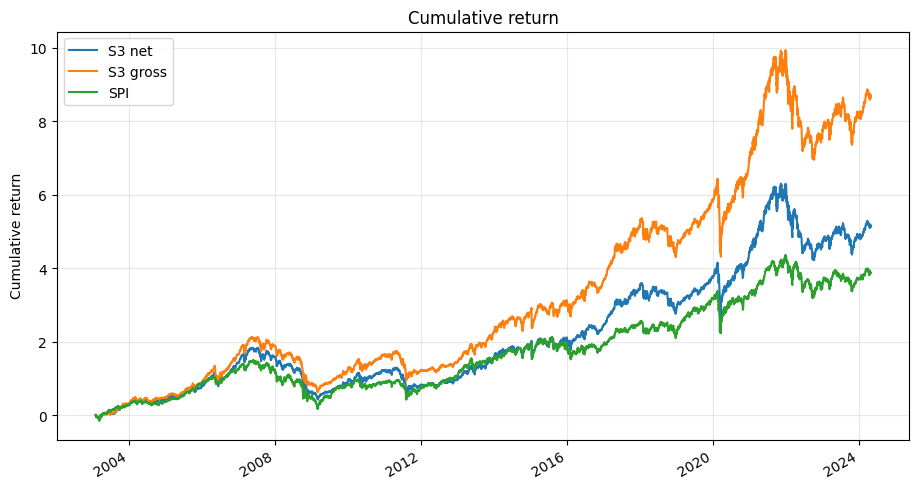

In [9]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Cumulative return')
ax.grid(alpha=0.3)
plt.show()

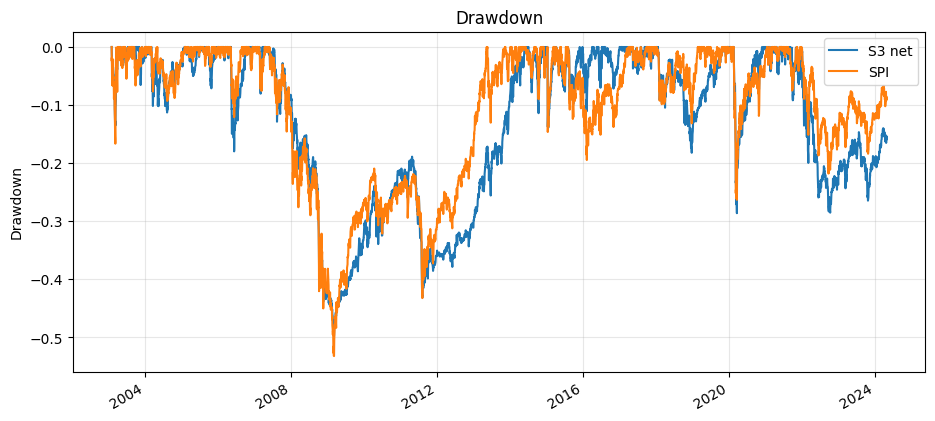

In [10]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    return wealth / wealth.cummax() - 1


ax = drawdown(comparison[['S3 net', 'SPI']]).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
ax.grid(alpha=0.3)
plt.show()

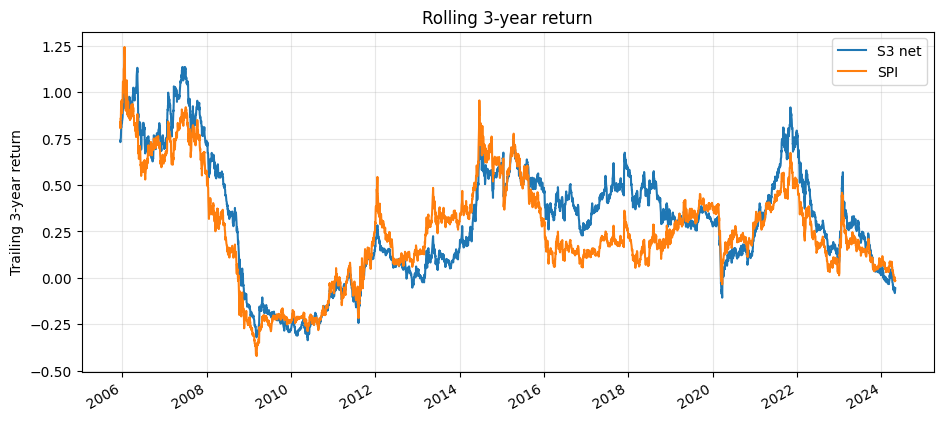

In [11]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return[['S3 net', 'SPI']].plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Trailing 3-year return')
ax.grid(alpha=0.3)
plt.show()

## 8. Statistics

In [12]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

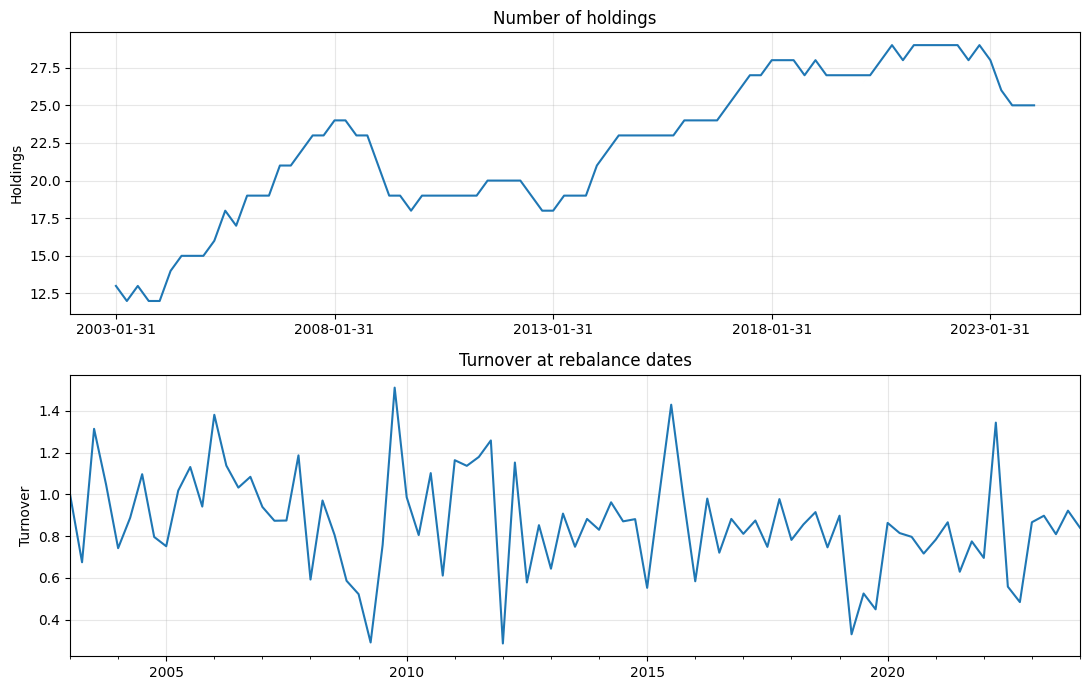

Average turnover: 0.865
Median turnover: 0.867


In [13]:
turnover_s3 = bt_s3.strategy.turnover(return_series=return_series, rescale=False)
turnover_s3.index = pd.to_datetime(turnover_s3.index)
turnover_s3.name = 'turnover'

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
weights_s3.gt(0).sum(axis=1).plot(ax=axes[0], title='Number of holdings')
axes[0].set_ylabel('Holdings')
axes[0].grid(alpha=0.3)
turnover_s3.plot(ax=axes[1], title='Turnover at rebalance dates')
axes[1].set_ylabel('Turnover')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Average turnover:', turnover_s3.mean().round(3))
print('Median turnover:', turnover_s3.median().round(3))

## 9. Selection Diagnostics

In [14]:
selection_counts = []
for rebdate in rebdates:
    bs_s3.build_selection(rebdate)
    binary = bs_s3.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

,return_history,gaps,min_volume,top_momentum,volatility_cap,beta_cap,selected_after_all_filters
2023-01-31,33.0,33.0,33.0,33.0,33.0,28.0,28.0
2023-04-30,32.0,32.0,32.0,32.0,32.0,26.0,26.0
2023-07-31,30.0,30.0,30.0,30.0,30.0,25.0,25.0
2023-10-31,30.0,30.0,30.0,30.0,30.0,25.0,25.0
2024-01-31,30.0,30.0,30.0,30.0,30.0,25.0,25.0


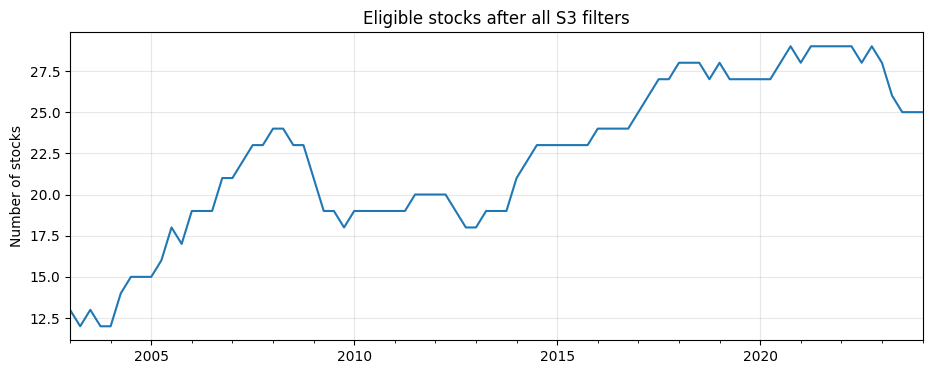

,count,mean,std,min,25%,50%,75%,max
return_history,85.0,26.541176,5.404039,15.0,23.0,27.0,32.0,34.0
gaps,85.0,26.541176,5.404039,15.0,23.0,27.0,32.0,34.0
min_volume,85.0,26.541176,5.404039,15.0,23.0,27.0,32.0,34.0
top_momentum,85.0,26.541176,5.404039,15.0,23.0,27.0,32.0,34.0
volatility_cap,85.0,26.541176,5.404039,15.0,23.0,27.0,32.0,34.0
beta_cap,85.0,22.211765,4.733604,12.0,19.0,23.0,27.0,29.0
selected_after_all_filters,85.0,22.211765,4.733604,12.0,19.0,23.0,27.0,29.0


In [15]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Eligible stocks after all S3 filters',
)
ax.set_ylabel('Number of stocks')
ax.grid(alpha=0.3)
plt.show()

selection_counts.describe().T

## 10. Summary

S3 buys high-momentum stocks after removing illiquid, high-volatility, and high-beta names. Weights are inverse-volatility with a stock cap.